In [2]:
import numpy as np
import string
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.utils import to_categorical
from numpy.linalg import norm

In [3]:
# Sample
text = """
The quick brown fox jumps over the lazy dog.
The fox is quick and the dog is lazy.
Machine learning is a part of artificial intelligence.
Deep learning is a part of machine learning.
Artificial intelligence is changing the world.
"""

# Convert text to lowercase and tokenize
words = text.lower().split()

print("Total words:", len(words))
print("Words:", words)

Total words: 40
Words: ['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog.', 'the', 'fox', 'is', 'quick', 'and', 'the', 'dog', 'is', 'lazy.', 'machine', 'learning', 'is', 'a', 'part', 'of', 'artificial', 'intelligence.', 'deep', 'learning', 'is', 'a', 'part', 'of', 'machine', 'learning.', 'artificial', 'intelligence', 'is', 'changing', 'the', 'world.']


In [4]:
# Remove punctuation
words = [
    word.strip(string.punctuation)
    for word in words
]

# Remove empty words
words = [word for word in words if word]

print("Total cleaned words:", len(words))
print("Cleaned words:", words)


Total cleaned words: 40
Cleaned words: ['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog', 'the', 'fox', 'is', 'quick', 'and', 'the', 'dog', 'is', 'lazy', 'machine', 'learning', 'is', 'a', 'part', 'of', 'artificial', 'intelligence', 'deep', 'learning', 'is', 'a', 'part', 'of', 'machine', 'learning', 'artificial', 'intelligence', 'is', 'changing', 'the', 'world']


In [ ]:
# Create vocabulary
unique_words: set[str] = set(words)

vocab: list[str] = sorted(unique_words)

vocab_size = len(vocab)

# Word to index -> used to convert words to numerical representation
word_to_index = {word: i for i, word in enumerate(vocab)}

# Index to word -> used to convert numerical representations back to words
index_to_word = {i: word for i, word in enumerate(vocab)}

print("Vocabulary Size:", vocab_size)
print("\nVocabulary:")
print(vocab)

Vocabulary Size: 20

Vocabulary:
['a', 'and', 'artificial', 'brown', 'changing', 'deep', 'dog', 'fox', 'intelligence', 'is', 'jumps', 'lazy', 'learning', 'machine', 'of', 'over', 'part', 'quick', 'the', 'world']


In [ ]:
# Context window size -> used for feature representation
window_size = 2

X = []
y = []

# Generate training examples
for i in range(window_size, len(words) - window_size):
	
    context_words = (
        words[i-window_size:i] +
        words[i+1:i+window_size+1]
    )

    target_word = words[i]

    # Convert context words to one-hot vectors
    context_vec tor = np.zeros(vocab_size)

    for word in context_words:
        context_vector[word_to_index[word]] += 1

    # Average the context vectors
    context_vector = context_vector / len(context_words)

    # Target word index
    target_index = word_to_index[target_word]

    X.append(context_vector)
    y.append(target_index)

X = np.array(X)
y = np.array(y)

# One-hot encode target
y = to_categorical(y, num_classes=vocab_size)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

NameError: name 'words' is not defined

In [6]:
print("Number of training examples:", len(X))

for i in range(min(5, len(X))):
    print("\nExample", i + 1)
    print("Input vector:", X[i])
    print("Target word:", index_to_word[np.argmax(y[i])])

Number of training examples: 36

Example 1
Input vector: [0.   0.   0.   0.   0.   0.   0.   0.25 0.   0.   0.25 0.   0.   0.
 0.   0.   0.   0.25 0.25 0.  ]
Target word: brown

Example 2
Input vector: [0.   0.   0.   0.25 0.   0.   0.   0.   0.   0.   0.25 0.   0.   0.
 0.   0.25 0.   0.25 0.   0.  ]
Target word: fox

Example 3
Input vector: [0.   0.   0.   0.25 0.   0.   0.   0.25 0.   0.   0.   0.   0.   0.
 0.   0.25 0.   0.   0.25 0.  ]
Target word: jumps

Example 4
Input vector: [0.   0.   0.   0.   0.   0.   0.   0.25 0.   0.   0.25 0.25 0.   0.
 0.   0.   0.   0.   0.25 0.  ]
Target word: over

Example 5
Input vector: [0.   0.   0.   0.   0.   0.   0.25 0.   0.   0.   0.25 0.25 0.   0.
 0.   0.25 0.   0.   0.   0.  ]
Target word: the


In [7]:
model = Sequential([
    Dense(50, input_shape=(vocab_size,), activation='relu'),
    Dense(vocab_size, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/Users/soni/Developer/learning-in-public/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 50)             │         1,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         1,020 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,070 (8.09 KB)

 Trainable params: 2,070 (8.09 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    X, y, epochs=300, batch_size=16, verbose=1
)

Epoch 1/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1111 - loss: 2.9928  
Epoch 2/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1389 - loss: 2.9835    
Epoch 3/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1389 - loss: 2.9753
Epoch 4/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1389 - loss: 2.9680
Epoch 5/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1389 - loss: 2.9611
Epoch 6/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1389 - loss: 2.9538
Epoch 7/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1667 - loss: 2.9468
Epoch 8/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1389 - loss: 2.9402    
Epoch 9/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1389 - loss: 2.9334
Epoch 10/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1667 - loss: 2.9263
Epoch 11/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1389 - loss: 2.9193
Epoch 12/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1667 - loss

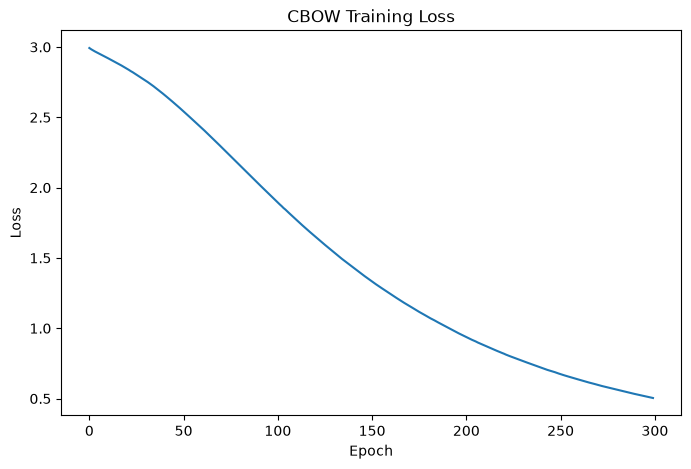

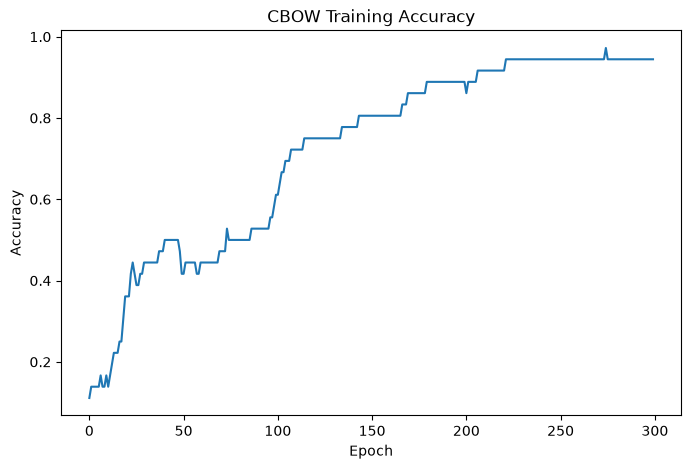

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CBOW Training Loss")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'])
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CBOW Training Accuracy")
plt.show()

In [10]:
def predict_word(context_words):

    context_vector = np.zeros(vocab_size)

    for word in context_words:
        if word in word_to_index:
            context_vector[word_to_index[word]] += 1

    context_vector = context_vector / len(context_words)

    prediction = model.predict(
        np.array([context_vector]),
        verbose=0
    )

    predicted_index = np.argmax(prediction)

    return index_to_word[predicted_index]

In [11]:
context = ["fox", "and", "the", "is"]

predicted_word = predict_word(context)

print("Context words:", context)
print("Predicted word:", predicted_word)

Context words: ['fox', 'and', 'the', 'is']
Predicted word: quick
